# Satellite density map — 30 days (TLE only)

Ground-track and RA–Dec sky density of the main GNSS constellations over a
**30-day window**, built from **TLEs only** (no RINEX, no flux, no radio
sources).

Each code cell uses `%%time` and reports the **wall time** at the end.

In [1]:
%%time
# ── Directory anchor: project root (CWD-independent) ──
# Ensures relative paths (e.g. Path("data")) resolve from the project root,
# regardless of where the Jupyter kernel started (notebooks/ or root).
import os

from radioskysims_core.paths import get_project_root

os.chdir(get_project_root())
print("cwd →", os.getcwd())

cwd → /share/lbarosi/RadioSkySimSuite
CPU times: user 3.98 s, sys: 124 ms, total: 4.1 s
Wall time: 1.37 s


In [2]:
%%time
# ── Reference parameters: 30-day window at a 30-minute step ──
from datetime import UTC, datetime, timedelta

# Reference date: 1 month ago (UTC).
REF_DATE = (datetime.now(UTC) - timedelta(days=30)).replace(microsecond=0)
print("Reference date (REF_DATE):", REF_DATE.isoformat())

# Simulation window: 30 days starting at REF_DATE, 30 min step.
# TimeRange.from_iso accepts naive ISO (UTC) — no timezone suffix.
from radioskysims_core.domain.common import FrequencyRange, TimeRange

_ISO_FMT = "%Y-%m-%dT%H:%M:%S"
TR = TimeRange.from_iso(
    REF_DATE.strftime(_ISO_FMT),
    (REF_DATE + timedelta(days=30)).strftime(_ISO_FMT),
    60 * 30,
)
print(
    "TimeRange (30 days, 30 min):",
    TR.to_datetime64().shape[0],
    "instants | resolution:",
    TR.resolution_sec,
    "s",
)

FR = FrequencyRange(min_mhz=1000.0, max_mhz=1250.0, resolution_mhz=0.5)

# Reference observer (BINGO — Uirapuru/RN region).
from radioskysims_core.domain.common import Observer

OBSERVER = Observer(lat=-6.2391, lon=-38.9296, height=440.0, timeframe=TR)

Reference date (REF_DATE): 2026-10-08T18:07:29+00:00
TimeRange (30 days, 30 min): 1441 instants | resolution: 1800.0 s
CPU times: user 1.31 ms, sys: 0 ns, total: 1.31 ms
Wall time: 1.31 ms


### Composition root (dependency injection)

The facades (`SatelliteOrchestrator`, `LocalSourcesOrchestrator` and
`RadioSourcesOrchestrator`) receive their concrete factories — Skyfield
tracks, analytical PSD and repositories — through the **composition root**.
This is done **once** here, before using the services.

In [3]:
%%time
# ── Composition root: inject concrete factories into the facades (DI) ──
from radioskysims_sources.bootstrap.builders import configure_facade_defaults

configure_facade_defaults()
print("Facades configured (Skyfield tracks + analytical PSD + repositories).")

Facades configured (Skyfield tracks + analytical PSD + repositories).
CPU times: user 270 ms, sys: 35 ms, total: 305 ms
Wall time: 304 ms


## Satellites (TLE)

Uses `SatelliteOrchestrator` with `REF_DATE` (the reference date) and the
30-day `TR` window. Requires PostgreSQL (`settings.toml`); if the local TLE
catalog is unavailable, the error is shown and the notebook continues.

In [4]:
%%time
# Satellites via SatelliteOrchestrator (facade) — TLE at the reference date
import pandas as pd
from radioskysims_sources import SatelliteOrchestrator

CONSTELLATIONS = ["GPS", "GALILEO", "BEIDOU", "GLONASS"]

try:
    sat_orch = SatelliteOrchestrator.create_from_constellation(
        CONSTELLATIONS,
        epoch=REF_DATE,
    )
    sats = sat_orch.satellites
    tles = sat_orch.get_tle()
    print(f"{len(sats)} satellites found in the catalog (deduplicated by NORAD ID).")
    print(f"{len(tles)} TLEs selected — one per satellite, closest to {REF_DATE:%Y-%m-%d}.")

    # Table ordered by constellation and NORAD ID.
    table = (
        pd.DataFrame(
            [
                {
                    "constellation": s.constellation,
                    "norad_id": s.norad_id,
                    "name": s.name,
                    "prn": s.prn,
                    "sv": s.sv,
                    "tle_epoch": s.epoch.isoformat(),
                }
                for s in sats
            ]
        )
        .sort_values(["constellation", "norad_id"])
        .reset_index(drop=True)
    )
    display(table)
except Exception as exc:
    print("[warning] satellite catalog unavailable —", type(exc).__name__, str(exc)[:200])

138 satellites found in the catalog (deduplicated by NORAD ID).
138 TLEs selected — one per satellite, closest to 2026-10-08.


,constellation,norad_id,name,prn,sv,tle_epoch
0,BEIDOU,36828,BEIDOU-2 IGSO-1 (C06),6,C06,2026-10-24T13:46:15.118176+00:00
1,BEIDOU,37210,BEIDOU-2 G4 (C04),4,C04,2026-10-08T18:28:22.569024+00:00
2,BEIDOU,37256,BEIDOU-2 IGSO-2 (C07),7,C07,2026-10-08T09:39:43.274016+00:00
3,BEIDOU,37384,BEIDOU-2 IGSO-3 (C08),8,C08,2026-10-08T18:23:49.257312+00:00
4,BEIDOU,37763,BEIDOU-2 IGSO-4 (C09),9,C09,2026-10-08T16:28:22.829376+00:00
...,...,...,...,...,...,...
133,GPS,55268,GPS BIII-6 (PRN 28),28,G28,2026-10-09T22:39:59.999616+00:00
134,GPS,62339,GPS BIII-7 (PRN 01),1,G01,2026-10-09T02:33:46.516032+00:00
135,GPS,64202,GPS BIII-8 (PRN 21),21,G21,2026-10-26T04:59:49.744896+00:00
136,GPS,67588,GPS BIII-9 (PRN 20),20,G20,2026-10-08T20:52:41.471616+00:00


CPU times: user 4.85 s, sys: 26.8 ms, total: 4.88 s
Wall time: 4.93 s


We provide two helpers below: a **ground-track** helper (sub-satellite
latitude/longitude from the TLEs) and an **RA–Dec sky map**. The RA–Dec map is
built separately for the four main constellations, using a standard angular
cell resolution. Track density per unit area is computed with the haversine
metric and shown as a 2 × 2 heatmap panel.

SatelliteAssembled(138 satélites [GPS BIIR-5 (PRN 22), GPS BIIR-8 (PRN 16), GPS BIIR-11 (PRN 19), GPS BIIR-13 (PRN 02), GPS BIIRM-1 (PRN 17), … (+133)]; tracks {'satellite': 138, 'time': 1441, 'xyz': 3}, signals {'satellite': 679, 'freq': 501})
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sats_30d_radec_density_2x2.png
CPU times: user 1min 35s, sys: 664 ms, total: 1min 36s
Wall time: 5.97 s


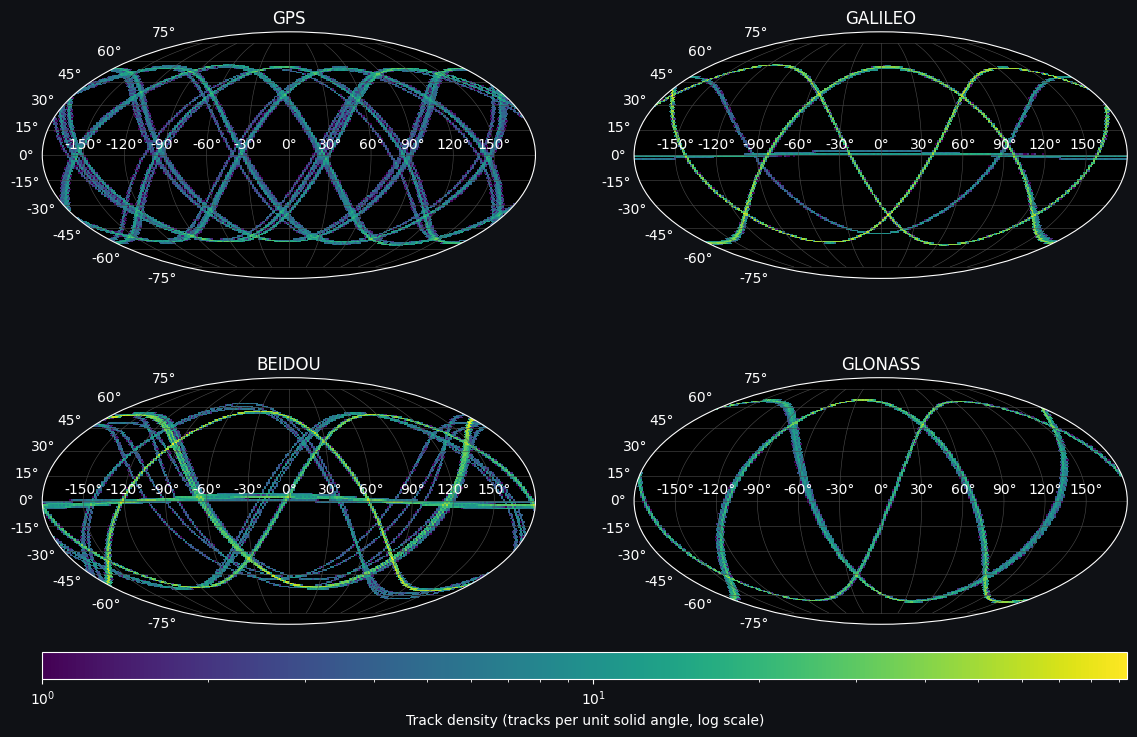

In [ ]:
%%time
# build: assemble the SatelliteAssembled (tracks only) over the 30-day window
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from radioskysims_viz import save_figure

DARK_BG = "#0f1115"


def radec_density(ds, constellation, bins_ra=180, bins_dec=90):
    """RA/Dec sky-map density (tracks per unit solid angle) of a constellation."""
    if "constellation" in ds.coords:
        mask = np.array([str(c).upper() == constellation.upper() for c in ds.constellation.values])
        ds = ds.isel(satellite=mask)
    pos = np.asarray(ds["positions"].values, dtype=float)  # (sat, time, 3)
    x, y, z = pos[..., 0], pos[..., 1], pos[..., 2]
    r = np.sqrt(x * x + y * y + z * z)
    ra = (np.degrees(np.arctan2(y, x)) % 360).ravel()
    dec = np.degrees(np.arcsin(z / r)).ravel()
    # 1/cos(dec) weights compensate the projected area (density per unit area).
    weights = 1.0 / np.cos(np.radians(dec))
    h, ra_edges, dec_edges = np.histogram2d(
        ra,
        dec,
        bins=[bins_ra, bins_dec],
        range=[[0.0, 360.0], [-90.0, 90.0]],
        weights=weights,
    )
    return h, ra_edges, dec_edges


res = 1

try:
    assembled = sat_orch.build(TR, FR)
    print(assembled)  # friendly __repr__ (N satellites + dims)

    # RA–Dec sky-map density in Mollweide projection, one panel per constellation.
    # Dark background + a single horizontal colorbar shared by the 2×2 grid.
    with plt.style.context("dark_background"):
        # Compute all panels first so they share one log color scale.
        panels = [
            radec_density(assembled.tracks, const, bins_ra=260 // res, bins_dec=180 // res)
            for const in CONSTELLATIONS
        ]
        vmax = max(float(np.max(h)) for h, _, _ in panels)
        # Log scale: the equatorial band is orders of magnitude denser than the
        # poles. Weights are >= 1, so vmin=1 is safe; zero cells are masked out.
        norm = mpl.colors.LogNorm(vmin=1.0, vmax=vmax)
        cmap = plt.get_cmap("viridis").copy()
        cmap.set_bad("none")  # zero-density cells → transparent (dark background)

        fig, axes = plt.subplots(2, 2, figsize=(14, 9), subplot_kw={"projection": "mollweide"})
        fig.patch.set_facecolor(DARK_BG)

        for ax, const, (h, ra_edges, dec_edges) in zip(
            axes.ravel(), CONSTELLATIONS, panels, strict=False
        ):
            # Mollweide expects RA centered on 0° (radians, wrapped to [-π, π]).
            ra_c = (ra_edges - 180.0) * np.pi / 180.0
            dec_c = dec_edges * np.pi / 180.0
            h_masked = np.ma.masked_where(h.T <= 0, h.T)
            im = ax.pcolormesh(ra_c, dec_c, h_masked, cmap=cmap, norm=norm, shading="auto")
            ax.set_title(const)
            ax.grid(True, color="0.3", lw=0.4)

        # Single shared colorbar, horizontal, at the bottom of the grid.
        cb = fig.colorbar(
            im, ax=axes, orientation="horizontal", fraction=0.045, pad=0.04, aspect=40
        )
        cb.set_label("Track density (tracks per unit solid angle, log scale)")
        # Mollweide axes are incompatible with tight_layout; the colorbar above
        # already reserves the bottom space, so no extra layout call is needed.
        save_figure(fig, "sats_30d_radec_density_2x2")
except Exception as exc:
    print(
        "[warning] satellite assembly/plot unavailable (Postgres?) —",
        type(exc).__name__,
        str(exc)[:200],
    )
